# Assignment 1 — Data visualisation and descriptive analytics report

<p class="lead">
Act as an analytics consultant for a restaurant: produce two summary tables and three figures from 244 restaurant bills in Python, then write a four-section business report that turns them into staffing and revenue recommendations.
</p>

*Adapted from the DATA 300 syllabus, Assignment 1 (Data visualization and descriptive analytics report). Brief rewritten for this classroom; the analysis runs offline in local JupyterLab.*

> **Graded work: Assignment 1 (6%, CLO 1, 2 and 3)**
>
> - **Set:** Wednesday 11 November (Day 2), after the Tableau lecture.
> - **Due:** **Sunday 15 November 2026, 23:59 China Standard Time**.
> - **Submit:** one PDF, `YourLastName_DATA300_Assignment1.pdf`, to the **DATA 300: Assignment 1** drop-box on **GAP (Moodle)**.
> - **Work:** individual. Online support is available over the weekend.

This notebook is both the **brief** (read it all first) and your **starter notebook**. Save your own copy before you change anything: **File → Save Notebook As…** → `YourLastName_DATA300_Assignment1.ipynb`, in the same folder as this notebook so that `data/tips.csv` is found.

---

## The scenario

You have joined **Bistro Analytics**, a consulting firm that helps restaurants run better. A busy client restaurant has given you its transaction records: for each bill, the **total bill**, the **tip**, the **party size**, the **shift** (lunch or dinner), the **day of the week**, and whether the bill payer was a smoker and their sex. There are **244 bills**; amounts are in US dollars.

The owner wants evidence for two decisions:

| Goal | The owner's question |
|---|---|
| **Labour scheduling** | When is revenue highest, so that the best service staff work the busiest shifts? |
| **Revenue growth and server retention** | How do tips behave, and can upselling raise both the restaurant's revenue and the servers' income? |

Your job is **descriptive analytics**: summarise what happened, show it clearly, and turn it into practical recommendations. You do not need to prove causes, and you should not claim them.

---

## What you must do

| Part | Task |
|---|---|
| 1 | Complete and run the code in this notebook so it produces **Table 1**, **Table 2**, **Figure 1**, **Figure 2** and **Figure 3** exactly as specified below |
| 2 | Write a **business report** with the four required sections, based on those tables and figures |
| 3 | Export the report and the executed notebook to PDF, combine them, and submit on GAP |

You are not expected to write a lot of new code. Each cell below already runs and gives you a **starting point**; the text above it says exactly what the finished table or figure must show. The changes are small: the pandas you used on Day 1 (`groupby`, `mean`, `sum`) and the chart rules from Day 2.

---

## Part 1: The analysis

### Setup

Run this cell first. It loads the libraries and the data from the bundled file, so no internet connection is needed.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv("data/tips.csv")

# The restaurant opens Thursday to Sunday. Keep the days in week order in every table and chart.
DAYS = ["Thur", "Fri", "Sat", "Sun"]
df["day"] = pd.Categorical(df["day"], categories=DAYS, ordered=True)

print("Rows (bills), columns:", df.shape)
print("Missing values in any column:", int(df.isna().sum().sum()))
df.head()

Rows (bills), columns: (244, 7)
Missing values in any column: 0


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


### Table 1: Average transaction metrics by day

**The finished table must show**, for each day (Thursday to Sunday, in that order): the average total bill, the average tip and the average party size, rounded to 2 decimals, with the column names `Avg Total Bill ($)`, `Avg Tip ($)` and `Avg Party Size`.

**Starting point:** the cell computes only the average total bill. Add the other two columns and rename all three.

In [2]:
print("--- Table 1: Average Transaction Metrics by Day ---")
day_summary = df.groupby("day", observed=True)[["total_bill"]].mean().round(2)
day_summary.columns = ["Avg Total Bill ($)"]
day_summary

--- Table 1: Average Transaction Metrics by Day ---


,Avg Total Bill ($)
day,
Thur,17.68
Fri,17.15
Sat,20.44
Sun,21.41


### Table 2: Total revenue by meal shift

**The finished table must show** the **total** (sum) of `total_bill` for Lunch and for Dinner, rounded to 2 decimals, in a column named `Total Revenue ($)`.

**Starting point:** the cell counts the **number of bills** in each shift. Change it so it adds up the bill amounts instead.

In [3]:
print("--- Table 2: Aggregate Revenue Breakdown by Meal Shift ---")
time_summary = df.groupby("time", observed=True)[["total_bill"]].count()   # counts bills: change this
time_summary.columns = ["Number of bills"]
time_summary

--- Table 2: Aggregate Revenue Breakdown by Meal Shift ---


,Number of bills
time,
Dinner,176
Lunch,68


### Figure 1: Total revenue by day of the week (bar chart)

**The finished figure must show** one bar per day (Thursday to Sunday) whose height is the **total** of `total_bill` for that day, with the title `Figure 1: Total Gross Revenue Generated by Day of Week`, the x-axis label `Day of Week` and the y-axis label `Total Revenue ($)`.

**Starting point:** the chart shows the **number of bills** per day. Change what is plotted and the labels. Keep the bars starting at zero.

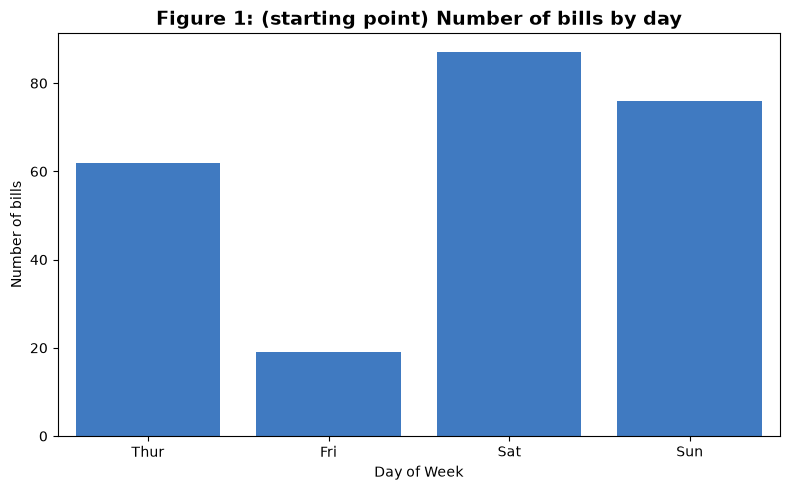

In [4]:
counts_by_day = df.groupby("day", observed=True)["total_bill"].count().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=counts_by_day, x="day", y="total_bill", color="#2a78d6")
plt.title("Figure 1: (starting point) Number of bills by day", fontsize=14, fontweight="bold")
plt.xlabel("Day of Week")
plt.ylabel("Number of bills")
plt.tight_layout()
plt.show()

### Figure 2: Tips at lunch and dinner (box plot)

**The finished figure must show** a box plot of the **tip** amount for each shift (Lunch and Dinner), with the title `Figure 2: Distribution of Server Tip Amounts: Lunch vs. Dinner`, the x-axis label `Meal Shift` and the y-axis label `Tip Amount ($)`.

**Starting point:** the box plot shows the **total bill** for each shift. Change the measure and the labels.

> **Reading a box plot**
>
> The line inside the box is the **median**; the box spans the middle half of the values (the **interquartile range**, IQR); the whiskers reach the furthest values within 1.5 × IQR of the box; points beyond them are drawn individually as possible **outliers**.

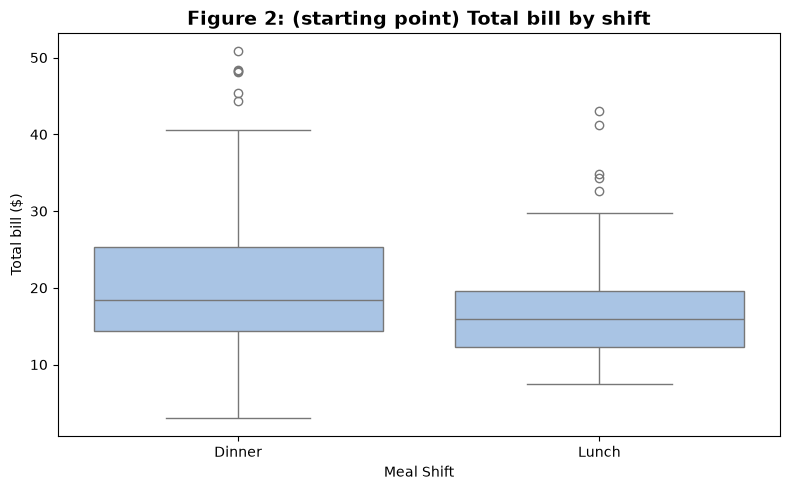

In [5]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="time", y="total_bill", color="#9fc3ee")
plt.title("Figure 2: (starting point) Total bill by shift", fontsize=14, fontweight="bold")
plt.xlabel("Meal Shift")
plt.ylabel("Total bill ($)")
plt.tight_layout()
plt.show()

### Figure 3: Bill size and tip (scatter plot with a trend line)

**The finished figure must show** each bill as a point, with `total_bill` on the x-axis and `tip` on the y-axis, **plus a straight-line (least-squares) trend line**. Use the title `Figure 3: Linear Relationship: Total Bill Size vs. Tip Amount`, the x-axis label `Total Bill Amount ($)` and the y-axis label `Tip Amount ($)`.

**Starting point:** the cell draws the points but no trend line and placeholder labels. Replace the scatter with `sns.regplot(...)`, which draws the points and the trend line together, and set the title and labels. Make the points semi-transparent so overlapping bills stay visible.

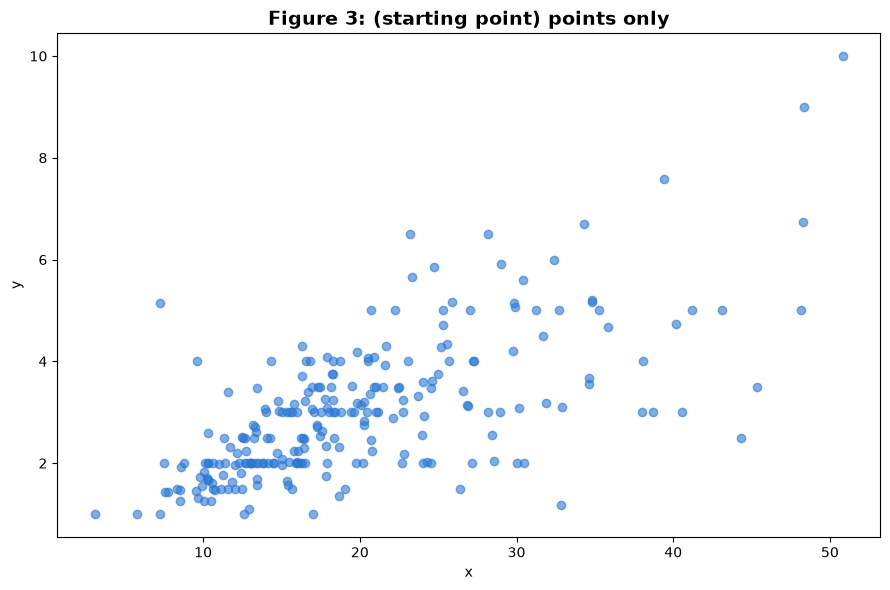

In [6]:
plt.figure(figsize=(9, 6))
plt.scatter(df["total_bill"], df["tip"], alpha=0.6, color="#2a78d6")
plt.title("Figure 3: (starting point) points only", fontsize=14, fontweight="bold")
plt.xlabel("x")
plt.ylabel("y")
plt.tight_layout()
plt.show()

> **Check before you write**
>
> - Restart the kernel and run every cell (**Kernel → Restart Kernel and Run All Cells**). Every table and figure must appear, with no errors.
> - Each table and figure matches its specification above: right measure, right aggregation (average or total), right title and labels.
> - The days run Thursday to Sunday.
> - You may add a cell with an extra number you want to quote in the report (for example the slope of the trend line or a median from Figure 2). Keep it short and label it.

---

## Part 2: The business report

Write the report in **Word** (or another editor that saves PDF). Use these **four headings exactly**, in this order. Write in full, connected paragraphs; only Section 4 uses bullet points. Refer to the evidence by name (Table 1, Figure 2…) and quote the numbers that support each point, with units.

### 1. Executive Summary

*One paragraph.* State the consulting context (Bistro Analytics and its client restaurant), the dataset (the tips data, N = 244 transactions) and the purpose: helping the owner schedule staff, grow revenue and keep good servers by acting on data.

### 2. Descriptive Data Overview

*One or two paragraphs.*

- From **Table 1**: which day has the highest **average bill**, and which has the highest **average tip**? Comment on party size where it helps explain the difference.
- From **Table 2**: compare total revenue at **lunch** and at **dinner**, and say how large the gap is.

### 3. Visual Insights & Graphical Trends

*Two or three paragraphs.*

- **Figure 1:** compare the weekdays (Thursday, Friday) with the weekend (Saturday, Sunday). Which days generate the most revenue?
- **Figure 2:** compare the **medians** and the **spread** (IQR) of tips at lunch and dinner. What does this mean for a server's earning potential on each shift? Comment on the high **outliers** above the upper whiskers.
- **Figure 3:** describe the direction and steepness of the trend line between bill and tip. What does this positive relationship suggest for **upselling** (for example appetisers, premium drinks, desserts)? Remember that an association is not proof that upselling **causes** higher tips.

### 4. Strategic Business Recommendations

*Two detailed bullet points*, each justified by the evidence above:

- **Recommendation 1, staffing and labour:** which days and shifts should get the strongest servers, so that peak demand is covered without slowing service?
- **Recommendation 2, revenue and server training:** a concrete upselling and service-training idea based on the bill–tip relationship, explaining how a higher average bill can benefit both the restaurant's revenue and the servers' tips.

> **Good practice from today's lectures**
>
> Lead with the finding, not the method ("Saturday and Sunday bring in most of the revenue…", not "Figure 1 is a bar chart that…"). Compare totals and averages carefully: a day can have a high **average** bill and still a low **total** if it has few bills. Write for the owner, a busy non-specialist.

---

## Part 3: Export and submit

| Step | What to do | File name |
|---|---|---|
| 1 | Save your Word report as PDF (all four sections, headings exactly as above, name and student ID on the first page) | `YourLastName_Report.pdf` |
| 2 | In JupyterLab, run **Kernel → Restart Kernel and Run All Cells** and check that every table and figure is visible | |
| 3 | Export the notebook: **File → Save and Export Notebook As → HTML**, open the HTML file in your browser, then **Print → Save as PDF** with **Background graphics** ticked (or use **File → Print** in JupyterLab) | `YourLastName_Jupyter.pdf` |
| 4 | Combine the two PDFs into one, **report first**, notebook second | `YourLastName_DATA300_Assignment1.pdf` |
| 5 | Log in to **GAP (Moodle)**, open the **DATA 300: Assignment 1** drop-box, upload the combined PDF and click **Submit** before the deadline | |

If you cannot combine PDFs on your computer, paste the notebook's tables and figures into the Word document after your report (as an appendix titled "Executed notebook output") and save everything as one PDF with the final file name.

---

## How it is marked

The assignment is marked out of 100 with the course's assignment rubric, then scaled to its 6% weight.

| Criterion | Points | What earns them here |
|---|---|---|
| **CLO 1**: principles of descriptive analytics for business decisions | 25 | Accurate descriptive findings from Tables 1–2 and Figures 1–3, linked to the owner's two goals |
| **CLO 2**: visualisation that communicates for decisions | 25 | Correct, readable figures with the required titles and labels; insights read correctly from each figure |
| **CLO 3**: computational problem-solving to find relationships | 30 | A notebook that runs top to bottom and produces exactly the specified tables and figures; a sound reading of the bill–tip relationship and the lunch–dinner comparison |
| **Professional formatting** | 10 | The four required headings, a combined PDF in the right order and file name, citations where you use sources (APA style) |
| **Academic writing** | 10 | Clear, organised paragraphs; correct grammar and terms; recommendations as two detailed bullet points |

Each criterion is judged on a scale from *exemplary* (full points) through *excellent*, *proficient*, *developing* and *unsatisfactory*; a missing submission scores 0.

---

## Final checklist

- [ ] My notebook is saved as `YourLastName_DATA300_Assignment1.ipynb` and runs from top to bottom without errors.
- [ ] Table 1, Table 2, Figure 1, Figure 2 and Figure 3 match their specifications.
- [ ] My report has the four headings exactly, quotes numbers with units, and has two detailed recommendations.
- [ ] I have not claimed that anything **causes** higher tips.
- [ ] One PDF, `YourLastName_DATA300_Assignment1.pdf`, report first, uploaded to GAP by **Sunday 15 November, 23:59 China Standard Time**.